
# BHARATH BUILDS
# 21 DAYS TO ML ENGINEER
# DAY 15 - K-MEDOIDS + HIERARCHICAL CLUSTERING

### Unsupervised Machine Learning | Customer Segmentation

**Learn. Implement. Interpret. Build.**

---

# 1. PROJECT OVERVIEW

Day 15 focuses on K-Medoids Clustering and Hierarchical Clustering, two important unsupervised machine learning algorithms.

In this session, we explore how clustering algorithms identify patterns and group similar customers based on their annual income and spending behavior.

We will implement both algorithms, visualize their cluster structures, evaluate clustering quality, and compare their results with K-Means Clustering from Day 14.

## Objective

To understand clustering strategies beyond K-Means, implement K-Medoids and Hierarchical Clustering using Python, evaluate the generated clusters, and interpret meaningful customer segments.

---

# 2. DATASET INFORMATION

## Dataset Name
Mall Customer Segmentation Dataset

## Dataset Source
[Download Dataset](https://raw.githubusercontent.com/abcom-mltutorials/mall/main/Mall_Customers.csv)

## Dataset Description

The Mall Customer Segmentation dataset contains customer demographic information, annual income, and spending scores.

The dataset is used to identify customer groups with similar spending patterns using unsupervised machine learning.

## Dataset Details

- Total Records: 200 customers
- Total Columns: 5
- Selected Features: 2
- Learning Type: Unsupervised Learning

## Features Used

| Feature | Description |
|---|---|
| Annual Income (k$) | Customer annual income in thousands of dollars |
| Spending Score (1-100) | Score assigned based on customer spending behavior |

CustomerID is excluded because it is a unique identifier and does not represent meaningful customer behavior.

---

# 3. LEARNING OBJECTIVES

By the end of this session, we will be able to:

- Understand the intuition behind K-Medoids Clustering.
- Differentiate between centroids and medoids.
- Understand how K-Medoids selects representative data points.
- Implement K-Medoids using Python.
- Understand Hierarchical Clustering.
- Explain Agglomerative and Divisive Clustering.
- Interpret dendrograms.
- Understand different linkage methods.
- Apply feature scaling for distance-based clustering.
- Evaluate clustering quality using Silhouette Score.
- Compare K-Means, K-Medoids, and Hierarchical Clustering.
- Interpret customer segments using cluster profiling.
- Identify the strengths and limitations of each clustering algorithm.

---

# 4. THEORETICAL CONCEPTS COVERED

## 4.1 K-Medoids Clustering

- K-Medoids intuition
- Medoid representation
- Actual data points as cluster representatives
- K-Medoids algorithm workflow

## 4.2 Medoids vs. Centroids

- Centroid calculation using the mean
- Medoid selection from actual data points
- Sensitivity to outliers
- Computational differences

## 4.3 Hierarchical Clustering

- Hierarchical clustering intuition
- Agglomerative clustering
- Divisive clustering
- Bottom-up and top-down approaches

## 4.4 Dendrogram

- Hierarchical cluster visualization
- Cluster merging distances
- Selecting a suitable number of clusters

## 4.5 Linkage Methods

- Single Linkage
- Complete Linkage
- Average Linkage
- Ward Linkage

## 4.6 Cluster Evaluation

- Silhouette Score
- Cluster compactness
- Cluster separation
- Cluster structure comparison

## 4.7 Limitations

- Sensitivity to feature scaling
- Effect of outliers
- Choosing the number of clusters
- Algorithm-specific computational complexity

---

# 5. PRACTICAL IMPLEMENTATION

The practical implementation will include:

1. Importing the required Python libraries.
2. Loading the Mall Customer Segmentation dataset.
3. Exploring the dataset using Pandas.
4. Selecting Annual Income and Spending Score.
5. Applying StandardScaler for feature scaling.
6. Implementing K-Medoids Clustering.
7. Visualizing clusters and medoids.
8. Evaluating K-Medoids using Silhouette Score.
9. Creating a dendrogram for Hierarchical Clustering.
10. Implementing Agglomerative Clustering.
11. Visualizing hierarchical clusters.
12. Evaluating Hierarchical Clustering using Silhouette Score.
13. Comparing K-Means, K-Medoids, and Hierarchical Clustering.
14. Creating cluster profiles.
15. Interpreting customer segmentation results.
16. Documenting observations and conclusions.

---

# 6. TOOLS AND FRAMEWORKS

| Tool / Library | Purpose |
|---|---|
| Python | Programming language |
| Google Colab | Development environment |
| Pandas | Data loading and data analysis |
| NumPy | Numerical computations |
| Matplotlib | Cluster visualization |
| Scikit-learn | K-Means, Agglomerative Clustering, StandardScaler, Silhouette Score |
| Scikit-learn-Extra | K-Medoids implementation |
| SciPy | Linkage calculation and dendrogram visualization |

## Development Environment

Google Colab Notebook

---

# 7. PROJECT WORKFLOW

```text
Mall Customer Segmentation Dataset
                |
                v
       Data Loading & Inspection
                |
                v
          Feature Selection
  Annual Income + Spending Score
                |
                v
          Feature Scaling
         StandardScaler
                |
       +--------+---------+
       |                  |
       v                  v
 K-Medoids Clustering   Hierarchical Clustering
       |                  |
       v                  v
 Cluster Visualization   Dendrogram
 Medoid Identification  Agglomerative Clustering
       |                  |
       v                  v
 Silhouette Score       Cluster Visualization
       |                  |
       +--------+---------+
                |
                v
     Compare with K-Means
                |
                v
       Cluster Profiling
                |
                v
    Customer Segment Interpretation
                |
                v
      Results & Documentation
                |
                v
             COMMIT
```

---

# 8. LEARNING PHILOSOPHY

EXPLAIN → IMPLEMENT → INTERPRET → DOCUMENT → COMMIT

- EXPLAIN: Understand the clustering algorithm and its intuition.
- IMPLEMENT: Apply the algorithm using Python.
- INTERPRET: Analyze clusters, visualizations, and evaluation scores.
- DOCUMENT: Record observations, comparisons, and conclusions.
- COMMIT: Save the practical work to the GitHub portfolio.

---

# 9. EXPECTED DELIVERABLES

- K-Medoids clustering implementation.
- Hierarchical clustering implementation.
- Dendrogram visualization.
- Cluster visualization for both algorithms.
- Silhouette Score evaluation.
- Comparison with K-Means Clustering.
- Cluster profiling and customer segment interpretation.
- Documented observations and final conclusion.

---

# DAY 15 PRACTICAL SESSION

Let's begin the implementation.

EXPLAIN → IMPLEMENT → INTERPRET → DOCUMENT → COMMIT


STEP 1 — Import Required Libraries

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import cdist

step 2 : load the dataset

In [48]:
from google.colab import files
uploaded=files.upload()

Saving Mall_Customers.csv to Mall_Customers (1).csv


In [49]:
file_name=next(iter(uploaded))
df=pd.read_csv(file_name)

print("Data set loaded successfully")

Data set loaded successfully


In [50]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [51]:
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [53]:
df.shape

(200, 5)

In [54]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [55]:
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


step3: select required features

In [56]:
feature_columns=[
    "Annual Income (k$)",
    "Spending Score (1-100)"

]

X=df[feature_columns].copy()

print("Selected features for clustering:")
print(feature_columns)
display(X.head())

Selected features for clustering:
['Annual Income (k$)', 'Spending Score (1-100)']


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


step4: feature scaling using Standard Scaler

In [57]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Data Shape:", X_scaled.shape)

print("Feature Means:", X_scaled.mean(axis=0).round(3))

print("Feature Standard Deviations:",
      X_scaled.std(axis=0).round(3))

print("Scaled Data Sample:")
print(X_scaled[:5])

Scaled Data Shape: (200, 2)
Feature Means: [-0. -0.]
Feature Standard Deviations: [1. 1.]
Scaled Data Sample:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


step 5: baseline model Kmeans clustering

In [58]:
K=5

kmeans=KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10

)

Kmeans_labels=kmeans.fit_predict(X_scaled)

print("Cluster Labels:", np.unique(Kmeans_labels))

print("Inertia:",round(kmeans.inertia_,3))

print("Silhouette Score:",round(silhouette_score(X_scaled,Kmeans_labels),3))



Cluster Labels: [0 1 2 3 4]
Inertia: 65.568
Silhouette Score: 0.555


step6: visualise k means

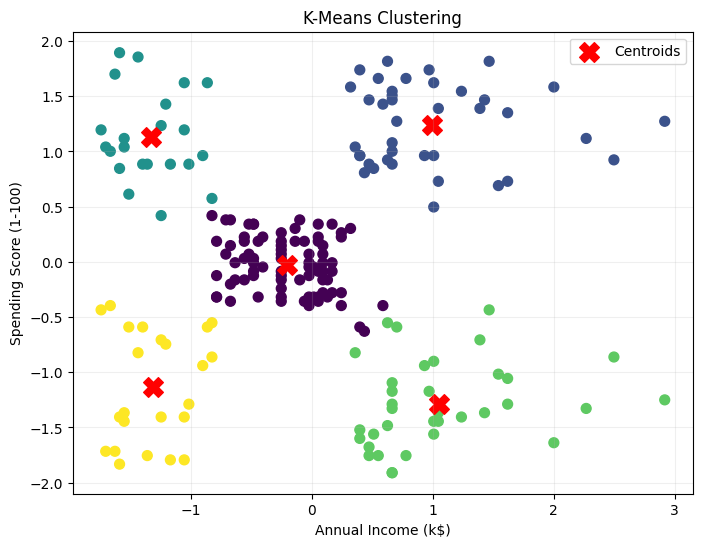

In [59]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=Kmeans_labels,
    cmap='viridis',
    s=50
)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    color='red',
    label='Centroids',
    s=200
)
plt.title('K-Means Clustering')
plt.xlabel(feature_columns[0])
plt.ylabel(feature_columns[1])
plt.legend()
plt.grid(alpha=0.2)
plt.show()






High Income + High Spending = High-value customers.



Low Income + High Spending = Active spending customers.



High Income + Low Spending = Potential customers.



Low Income + Low Spending = Budget-conscious customers.



Medium Income + Medium Spending = Average customers.

step7 : understanding of medoid amd centroid

In [60]:
# example points
points=np.array([
    [2,3],
    [3,4],
    [4,3],
    [10,10],
    [11,12]
])

# centroid
centroid=np.mean(points,axis=0)

# medoid
distance_matrix=cdist(points,points)

total_distance=distance_matrix.sum(axis=1)

medoid_index=np.argmin(total_distance)

medoid=points[medoid_index]

print("Centroid:",centroid)
print("Medoid:",medoid)

Centroid: [6.  6.4]
Medoid: [3 4]


step 8 : implement k- medoid


In [61]:
def k_medoids_pam(X, n_clusters=5,
                  max_iter=100,
                  random_state=42):

    rng = np.random.default_rng(random_state)

    n_samples = X.shape[0]

    # Step 1: Initialize medoids
    medoid_indices = rng.choice(
        n_samples,
        size=n_clusters,
        replace=False
    )

    # Step 2: Calculate pairwise distances
    distances = cdist(X, X, metric="euclidean")

    # Step 3: Calculate clustering cost
    def total_cost(indices):
        return distances[:, indices].min(axis=1).sum()

    current_cost = total_cost(medoid_indices)

    # Step 4: Try swapping medoids
    for iteration in range(max_iter):

        improved = False

        non_medoid_indices = np.setdiff1d(
            np.arange(n_samples),
            medoid_indices
        )

        for medoid_position in range(n_clusters):

            for candidate in non_medoid_indices:

                proposed = medoid_indices.copy()

                proposed[medoid_position] = candidate

                proposed_cost = total_cost(proposed)

                if proposed_cost < current_cost:

                    medoid_indices = proposed

                    current_cost = proposed_cost

                    improved = True

                    break

            if improved:
                break

        if not improved:
            print("Converged at iteration:", iteration + 1)
            break

    # Step 5: Assign final cluster labels
    final_distances = distances[:, medoid_indices]

    labels = final_distances.argmin(axis=1)

    return labels, medoid_indices, current_cost

STEP 9 — Fit K-Medoids on Customer Segmentation Dataset

In [62]:

kmedoids_labels, medoid_indices, kmedoid_cost = k_medoids_pam(
    X_scaled,
    n_clusters=5,
    max_iter=100,
    random_state=42
)

print("K medoids completeed")

print("cluster labels:",np.unique(kmedoids_labels))

print("medoid indices:",medoid_indices)

print("total cost:",round(kmedoid_cost,3))

print("Silhouette Score:",round(silhouette_score(X_scaled,kmedoids_labels),3))



Converged at iteration: 35
K medoids completeed
cluster labels: [0 1 2 3 4]
medoid indices: [176  24 161  15  80]
total cost: 100.72
Silhouette Score: 0.556


In [63]:
# display actual customer records slecected as medoids
medoids_original=X.iloc[medoid_indices]

print("Medoids:")
display(medoids_original)

Medoids:


,Annual Income (k$),Spending Score (1-100)
176,88,15
24,28,14
161,79,83
15,20,79
80,54,51


step 10 : visualisation of k medoids clustering

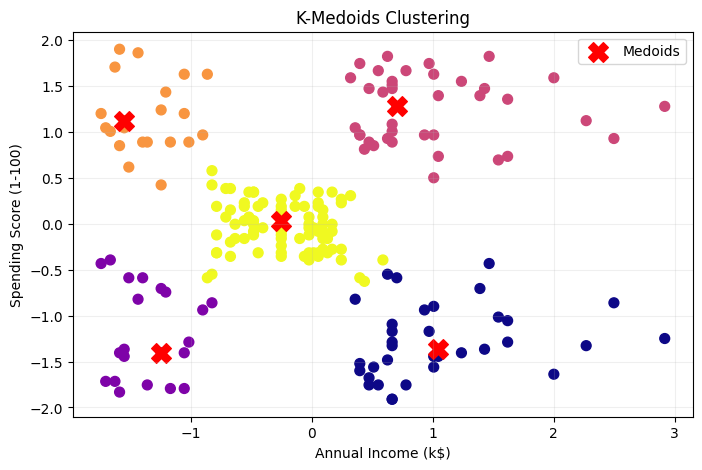

In [64]:
plt.figure(figsize=(8,5))

plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=kmedoids_labels,
    cmap='plasma',
    s=50
)

plt.scatter(
    X_scaled[medoid_indices,0],
    X_scaled[medoid_indices,1],
    marker='X',
    color='red',
    label='Medoids',
    s=200
)

plt.title('K-Medoids Clustering')
plt.xlabel(feature_columns[0])
plt.ylabel(feature_columns[1])
plt.legend()
plt.grid(alpha=0.2)
plt.show()

STEP 11 — Agglomerative Hierarchical Clustering


Agglomerative clustering is a bottom-up clustering algorithm.
1. Each customer starts as an individual cluster.
2. Find the closest pair of clusters.
3. Merge them.
4. Repeat until the specified cluster count is reached.

In [65]:
agglo=AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

agglo_labels=agglo.fit_predict(X_scaled)

print("Cluster Labels:",np.unique(agglo_labels))

print("Silhouette Score:",round(silhouette_score(X_scaled,agglo_labels),3))

Cluster Labels: [0 1 2 3 4]
Silhouette Score: 0.554


STEP 12 — Visualize Agglomerative Clustering


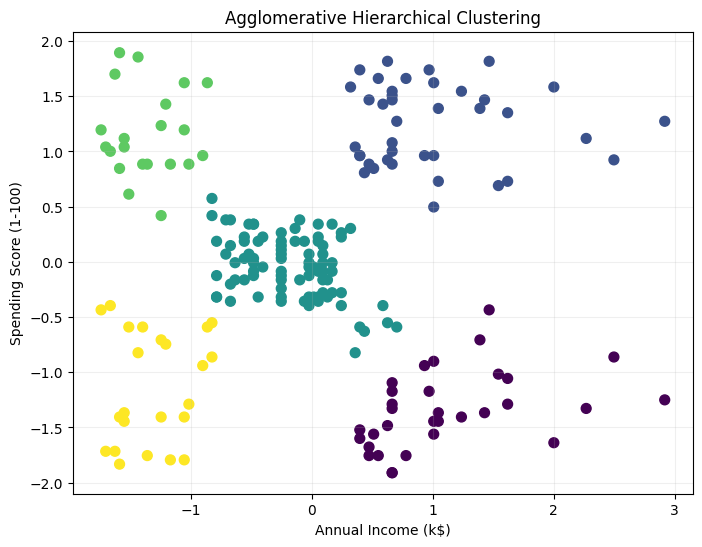

In [66]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=agglo_labels,
    cmap='viridis',
    s=50
)
plt.title('Agglomerative Hierarchical Clustering')
plt.xlabel(feature_columns[0])
plt.ylabel(feature_columns[1])
plt.grid(alpha=0.2)
plt.show()

step 13: Dendogram visualization


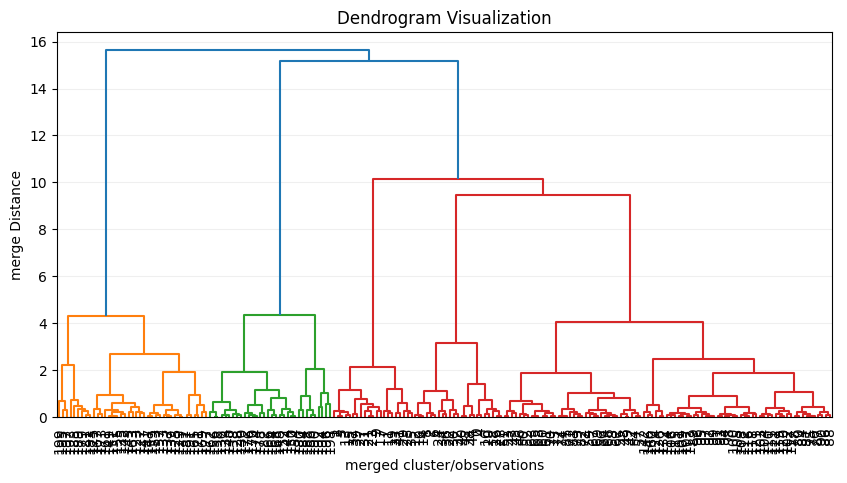

In [67]:
Z=linkage(
    X_scaled,
    method='ward',
    metric='euclidean'
)

plt.figure(figsize=(10,5))
dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=10,
)

plt.title('Dendrogram Visualization')
plt.xlabel('merged cluster/observations')
plt.ylabel('merge Distance')
plt.grid(axis="y",alpha=0.2)
plt.show()

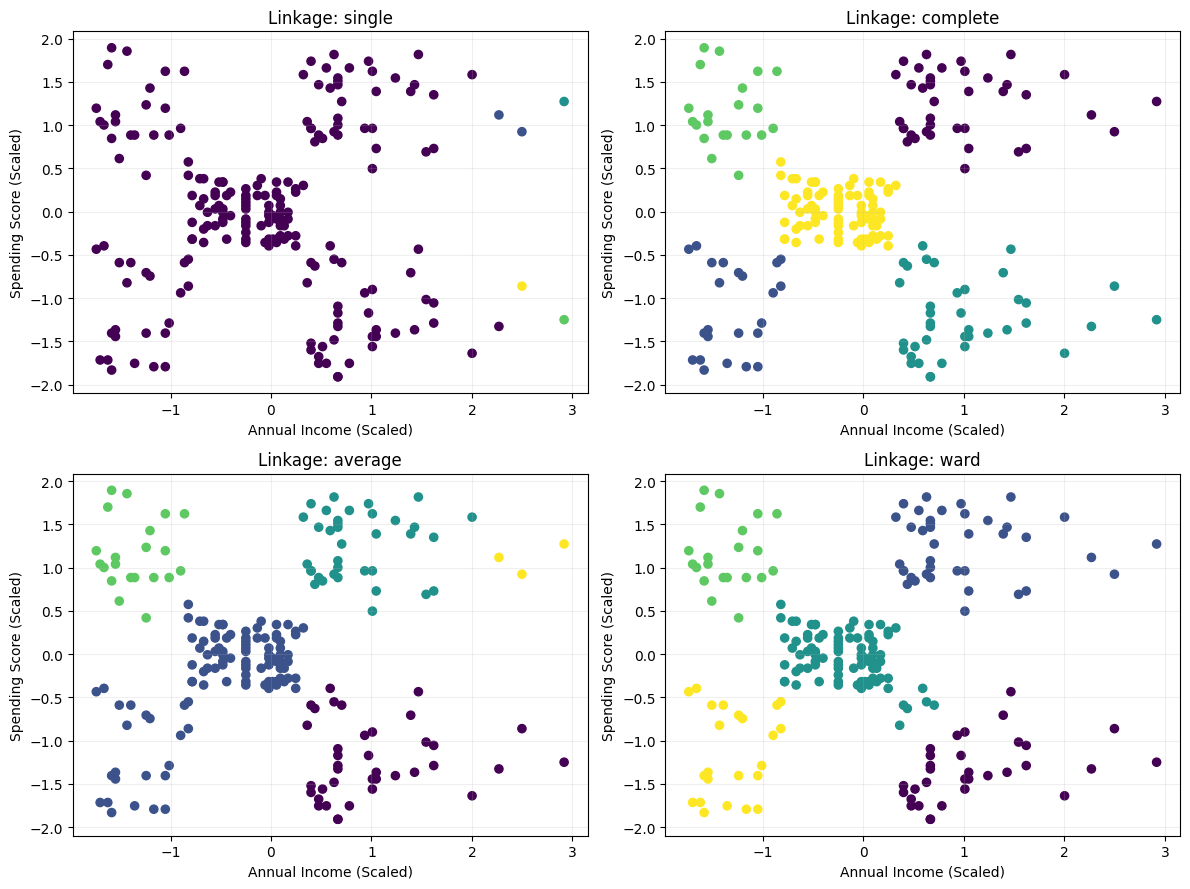

In [68]:
linkage_methods = [
    "single",
    "complete",
    "average",
    "ward"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9)
)

axes = axes.ravel()

for ax, method in zip(axes, linkage_methods):

    model = AgglomerativeClustering(
        n_clusters=K,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)

    ax.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=35
    )

    ax.set_title(f"Linkage: {method}")

    ax.set_xlabel("Annual Income (Scaled)")
    ax.set_ylabel("Spending Score (Scaled)")

    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

step14: compare KMEANS, KMEDOID,AGGLOMERATIVE CLUSTERING

In [76]:
comparison = pd.DataFrame({
    "Method": [
        "K-Means",
        "K-Medoids",
        "Agglomerative Ward"
    ],

    "Silhouette Score": [
        silhouette_score(X_scaled, Kmeans_labels),
        silhouette_score(X_scaled, kmedoids_labels),
        silhouette_score(X_scaled, agglo_labels)
    ],

    "Representative": [
        "Centroid",
        "Actual Medoid",
        "Hierarchy"
    ],

    "Cluster Count": [
        K,
        K,
        K
    ]
})

comparison["Silhouette Score"] = comparison[
    "Silhouette Score"
].round(3)

display(comparison)

,Method,Silhouette Score,Representative,Cluster Count
0,K-Means,0.555,Centroid,5
1,K-Medoids,0.556,Actual Medoid,5
2,Agglomerative Ward,0.554,Hierarchy,5


step 15: interpret customer cluster profiles


In [83]:

def cluster_profile(X, labels, method_name):

    profile = X.copy()
    profile["cluster"] = labels

    summary = profile.groupby("cluster").agg(
        customer_count=("cluster", "count"),

        avg_annual_income=("Annual Income (k$)", "mean"),
        avg_spending_score=("Spending Score (1-100)", "mean"),

        median_annual_income=("Annual Income (k$)", "median"),
        median_spending_score=("Spending Score (1-100)", "median")
    ).round(2)

    summary["method"] = method_name

    return summary


In [84]:
kmeans_profile = cluster_profile(
    X,
    Kmeans_labels,
    "K-Means"
)

kmedoids_profile = cluster_profile(
    X,
    kmedoids_labels,
    "K-Medoids"
)

agglo_profile = cluster_profile(
    X,
    agglo_labels,
    "Agglomerative"
)

In [88]:
print("K-Means Cluster Profile:")
display(kmeans_profile)

print("K-Medoids Cluster Profile:")
display(kmedoids_profile)

print("Agglomerative Cluster Profile:")
display(agglo_profile)

K-Means Cluster Profile:


,customer_count,avg_annual_income,avg_spending_score,median_annual_income,median_spending_score,method
cluster,,,,,,
0,81,55.30,49.52,54.0,50.0,K-Means
1,39,86.54,82.13,79.0,83.0,K-Means
2,22,25.73,79.36,24.5,77.0,K-Means
3,35,88.20,17.11,85.0,16.0,K-Means
4,23,26.30,20.91,25.0,17.0,K-Means


K-Medoids Cluster Profile:


,customer_count,avg_annual_income,avg_spending_score,median_annual_income,median_spending_score,method
cluster,,,,,,
0,35,88.20,17.11,85.0,16.0,K-Medoids
1,21,25.14,19.52,24.0,15.0,K-Medoids
2,39,86.54,82.13,79.0,83.0,K-Medoids
3,21,25.10,80.05,24.0,77.0,K-Medoids
4,84,54.70,49.37,54.0,49.5,K-Medoids


Agglomerative Cluster Profile:


,customer_count,avg_annual_income,avg_spending_score,median_annual_income,median_spending_score,method
cluster,,,,,,
0,32,89.41,15.59,86.5,15.0,Agglomerative
1,39,86.54,82.13,79.0,83.0,Agglomerative
2,85,55.81,49.13,57.0,49.0,Agglomerative
3,21,25.10,80.05,24.0,77.0,Agglomerative
4,23,26.30,20.91,25.0,17.0,Agglomerative


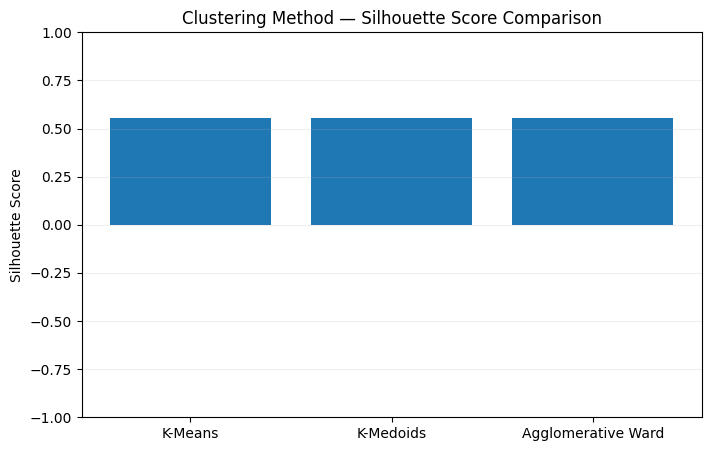

In [89]:
methods = [
    "K-Means",
    "K-Medoids",
    "Agglomerative Ward"
]

scores = [
    silhouette_score(X_scaled, Kmeans_labels),
    silhouette_score(X_scaled, kmedoids_labels),
    silhouette_score(X_scaled, agglo_labels)
]

plt.figure(figsize=(8, 5))

plt.bar(methods, scores)

plt.title("Clustering Method — Silhouette Score Comparison")

plt.ylabel("Silhouette Score")

plt.ylim(-1, 1)

plt.grid(axis="y", alpha=0.2)

plt.show()

In [90]:
observations = {
    "K-Means": [
        "Uses mean-based centroids",
        "Efficient for compact clusters",
        "Sensitive to outliers and initialization"
    ],

    "K-Medoids": [
        "Uses actual data points as medoids",
        "Can be more robust to extreme values",
        "Computationally expensive for larger datasets"
    ],

    "Agglomerative Clustering": [
        "Builds a bottom-up hierarchy",
        "Dendrogram helps understand cluster merging",
        "Sensitive to linkage method and scaling"
    ]
}

for method, notes in observations.items():

    print(f"\n{method}")

    for note in notes:
        print("-", note)


K-Means
- Uses mean-based centroids
- Efficient for compact clusters
- Sensitive to outliers and initialization

K-Medoids
- Uses actual data points as medoids
- Can be more robust to extreme values
- Computationally expensive for larger datasets

Agglomerative Clustering
- Builds a bottom-up hierarchy
- Dendrogram helps understand cluster merging
- Sensitive to linkage method and scaling



# 📊 DAY 15 — CLUSTER PROFILE INTERPRETATION

## 1. K-Means Cluster Profile Interpretation

- **Cluster 0 — Average Customers:** 81 customers with moderate annual income (55.30k) and moderate spending score (49.52). These customers show balanced spending behavior.
- **Cluster 1 — High-Income, High-Spending Customers:** 39 customers with high income (86.54k) and high spending score (82.13). They represent a valuable customer segment.
- **Cluster 2 — Low-Income, High-Spending Customers:** 22 customers with lower income (25.73k) but high spending score (79.36). They spend actively despite their lower income.
- **Cluster 3 — High-Income, Low-Spending Customers:** 35 customers with high income (88.20k) and low spending score (17.11). They may have potential for targeted engagement.
- **Cluster 4 — Low-Income, Low-Spending Customers:** 23 customers with lower income (26.30k) and low spending score (20.91). Their spending activity is relatively low.

## 2. K-Medoids Cluster Profile Interpretation

- **Cluster 0 — High-Income, Low-Spending Customers:** 35 customers with high income (88.20k) and low spending score (17.11).
- **Cluster 1 — Low-Income, Low-Spending Customers:** 21 customers with income (25.14k) and spending score (19.52).
- **Cluster 2 — High-Income, High-Spending Customers:** 39 customers with income (86.54k) and high spending score (82.13).
- **Cluster 3 — Low-Income, High-Spending Customers:** 21 customers with income (25.10k) and high spending score (80.05).
- **Cluster 4 — Average Customers:** 84 customers with moderate income (54.70k) and moderate spending score (49.37).

## 3. Agglomerative Cluster Profile Interpretation

- **Cluster 0 — High-Income, Low-Spending Customers:** 32 customers with high income (89.41k) and low spending score (15.59).
- **Cluster 1 — High-Income, High-Spending Customers:** 39 customers with income (86.54k) and spending score (82.13).
- **Cluster 2 — Average Customers:** 85 customers with moderate income (55.81k) and moderate spending score (49.13).
- **Cluster 3 — Low-Income, High-Spending Customers:** 21 customers with income (25.10k) and high spending score (80.05).
- **Cluster 4 — Low-Income, Low-Spending Customers:** 23 customers with income (26.30k) and low spending score (20.91).

---

# 🔍 FINAL COMPARATIVE INTERPRETATION

### Key Observations

1. **High-Income, High-Spending Segment:** All three algorithms identify a similar group of 39 customers with high income and high spending scores.
2. **Average Customer Segment:** K-Means identifies 81 customers, K-Medoids identifies 84, and Agglomerative identifies 85 customers in the moderate income and spending group.
3. **Low-Income, High-Spending Segment:** All methods identify approximately 21–22 customers with lower income but high spending scores.
4. **High-Income, Low-Spending Segment:** All algorithms identify customers with high income but relatively low spending scores.
5. **Low-Income, Low-Spending Segment:** The algorithms identify a similar customer group with low income and low spending activity.

### 🧠 Humanized Conclusion

Although K-Means, K-Medoids, and Agglomerative Clustering use different clustering strategies, their customer segmentation results are highly similar in this dataset.

All three algorithms identify five meaningful customer behavior patterns:

- High income + High spending
- High income + Low spending
- Low income + High spending
- Low income + Low spending
- Moderate income + Moderate spending

The main difference is the number of customers assigned to the moderate customer segment and some minor variations in cluster membership.

**Final takeaway:** Different clustering algorithms can discover similar patterns in the same dataset, even when their underlying mechanisms are different. Cluster IDs may differ, but the customer behavior patterns remain largely consistent.
